In [1]:
import torch
import torch.nn.functional as F

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
words = open('names.txt').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {c : i+1 for i, c in enumerate(chars)} # create a mapping from character to index, starting from 1
stoi['.'] = 0
itos = {i : c for c, i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [6]:
block_size = 3
X, Y = [], []

for w in words[:5]:
    print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '-->', itos[ix])
        context = context[1:] + [ix]


X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... --> e
..e --> m
.em --> m
emm --> a
mma --> .
olivia
... --> o
..o --> l
.ol --> i
oli --> v
liv --> i
ivi --> a
via --> .
ava
... --> a
..a --> v
.av --> a
ava --> .
isabella
... --> i
..i --> s
.is --> a
isa --> b
sab --> e
abe --> l
bel --> l
ell --> a
lla --> .
sophia
... --> s
..s --> o
.so --> p
sop --> h
oph --> i
phi --> a
hia --> .


In [7]:
X[0], X[1], X[2], X[3]

(tensor([0, 0, 0]),
 tensor([0, 0, 5]),
 tensor([ 0,  5, 13]),
 tensor([ 5, 13, 13]))

In [8]:
Y[0], Y[1], Y[2], Y[3]

(tensor(5), tensor(13), tensor(13), tensor(1))

In [9]:
# Embedding matrix or lookup table
C = torch.randn((27, 2))
C

tensor([[ 0.2511,  1.1975],
        [ 0.5815, -0.9154],
        [ 1.0386, -1.1327],
        [ 1.2530,  0.8040],
        [-1.4787, -0.5965],
        [ 0.6369, -1.1263],
        [ 0.7984, -0.3820],
        [ 0.1223,  0.4598],
        [ 0.2020, -1.3759],
        [ 0.6506,  1.3848],
        [-0.2711, -0.0168],
        [-0.5102, -0.3367],
        [-0.1578,  0.9557],
        [ 0.0991, -0.4313],
        [-1.1413, -0.1110],
        [-0.7559, -0.3769],
        [-1.6808,  1.3737],
        [ 1.5578, -3.0477],
        [ 1.5399,  2.3457],
        [ 0.2460, -0.3755],
        [-0.1637, -1.1665],
        [ 0.0582,  1.7770],
        [ 0.0229,  0.5486],
        [ 0.4897, -1.8478],
        [ 1.4581, -0.1963],
        [-0.6713, -1.2267],
        [ 0.6894,  0.4380]])

In [10]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([ 0.6369, -1.1263])

In [11]:
C[5] # we will use this method

tensor([ 0.6369, -1.1263])

In [12]:
C[[1, 2, 3, 3, 3]]

tensor([[ 0.5815, -0.9154],
        [ 1.0386, -1.1327],
        [ 1.2530,  0.8040],
        [ 1.2530,  0.8040],
        [ 1.2530,  0.8040]])

In [13]:
C[X].shape

torch.Size([32, 3, 2])

In [14]:
print(X[13, 2])
print(C[X][13, 2])
print(C[1])

tensor(1)
tensor([ 0.5815, -0.9154])
tensor([ 0.5815, -0.9154])


In [15]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [16]:
# number of neurons in input layer = 3 * 2 = 6
# lets use 100 neurons in hidden layer
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [17]:
# we can not directly do
emb @ W1 + b1
# because emb([32, 3, 2]) can not be multiplied to W1([6, 100])
# we need to somehow merge last 2 dim of emb

RuntimeError: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [ ]:
# we want to merge all the char embeddings of each context as one vector 
emb[0]

tensor([[-0.1115,  1.5520],
        [-0.1115,  1.5520],
        [-0.1115,  1.5520]])

In [ ]:
emb[:, 0, :].shape # this is 0th chracter of all the context of all the words

torch.Size([32, 2])

In [ ]:
# Method 1:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], dim=1).shape # this is not good way because we need to change this code if we change block size(context size)

torch.Size([32, 6])

In [ ]:
# Method 2
torch.unbind(emb, dim=1) # output is (emb[:, 0, :], emb[:, 1, :], emb[:, 2, :], ...)

(tensor([[-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [ 0.1077, -1.1957],
         [ 2.2027, -0.7732],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [ 0.6241, -0.0239],
         [-0.1567,  0.3697],
         [ 0.9764, -0.1079],
         [-0.7557, -1.3627],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.5964,  0.0734],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [ 0.9764, -0.1079],
         [-0.7407,  0.2762],
         [-0.5964,  0.0734],
         [-1.3550,  0.5989],
         [ 0.1077, -1.1957],
         [-0.1567,  0.3697],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [-0.7407,  0.2762],
         [ 0.6241, -0.0239],
         [ 0.6139,  0.5407],
         [ 2.0487,  0.6438]]),
 tensor([[-0.1115,  1.5520],
         [-0.1115,  1.5520],
         [ 0

In [ ]:
torch.cat(torch.unbind(emb, dim=1), dim=1).shape 

torch.Size([32, 6])

In [ ]:
# Method 3: Most efficient
emb.view(32, 6)

tensor([[-0.1115,  1.5520, -0.1115,  1.5520, -0.1115,  1.5520],
        [-0.1115,  1.5520, -0.1115,  1.5520,  0.1077, -1.1957],
        [-0.1115,  1.5520,  0.1077, -1.1957,  2.2027, -0.7732],
        [ 0.1077, -1.1957,  2.2027, -0.7732,  2.2027, -0.7732],
        [ 2.2027, -0.7732,  2.2027, -0.7732, -0.5964,  0.0734],
        [-0.1115,  1.5520, -0.1115,  1.5520, -0.1115,  1.5520],
        [-0.1115,  1.5520, -0.1115,  1.5520,  0.6241, -0.0239],
        [-0.1115,  1.5520,  0.6241, -0.0239, -0.1567,  0.3697],
        [ 0.6241, -0.0239, -0.1567,  0.3697,  0.9764, -0.1079],
        [-0.1567,  0.3697,  0.9764, -0.1079, -0.7557, -1.3627],
        [ 0.9764, -0.1079, -0.7557, -1.3627,  0.9764, -0.1079],
        [-0.7557, -1.3627,  0.9764, -0.1079, -0.5964,  0.0734],
        [-0.1115,  1.5520, -0.1115,  1.5520, -0.1115,  1.5520],
        [-0.1115,  1.5520, -0.1115,  1.5520, -0.5964,  0.0734],
        [-0.1115,  1.5520, -0.5964,  0.0734, -0.7557, -1.3627],
        [-0.5964,  0.0734, -0.7557, -1.3

In [ ]:
emb.view(32, 6) == torch.cat(torch.unbind(emb, dim=1), dim=1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, T

In [ ]:
# so calculate hidden state : -1 means torch will infer that dim
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h.shape # column 0 is output of 0th neuron for each of 32 input examples(X)
# or alternatively, 0th row of h is output of all 100 neurons for 0th training example

torch.Size([32, 100])

In [ ]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [ ]:
logits = h @ W2 + b2
logits.shape # 27 size vector per training example

torch.Size([32, 27])

In [ ]:
counts = logits.exp()
probs = counts / counts.sum(dim=1, keepdim=True)

In [ ]:
probs.shape

torch.Size([32, 27])

In [ ]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [ ]:
# pluck out the probability assign for correct option(Y[i]) from each row of probs
probs[torch.arange(32), Y] # => row 0 col 5, row 1 col 13, row 2 col 13, ...

tensor([2.8364e-15, 1.0236e-02, 9.9777e-01, 4.9370e-13, 1.2311e-10, 1.2173e-21,
        7.7889e-06, 2.8816e-12, 1.8937e-01, 2.8295e-07, 1.6908e-12, 3.1336e-04,
        1.1539e-20, 9.0690e-01, 3.5699e-10, 2.2015e-04, 4.5916e-19, 9.1207e-05,
        7.3651e-11, 2.3495e-10, 6.6499e-07, 1.8960e-14, 2.8848e-09, 4.1481e-11,
        6.0442e-13, 2.4554e-06, 7.6008e-16, 1.5265e-11, 4.5903e-09, 1.2624e-20,
        1.9229e-15, 3.8484e-14])

In [ ]:
loss = -probs[torch.arange(32), Y].log().mean()
loss

tensor(22.5252)

In [ ]:
############## Putting everything here

In [ ]:
block_size = 3
X, Y = [], []

for w in words:
    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '-->', itos[ix])
        context = context[1:] + [ix]


X = torch.tensor(X)
Y = torch.tensor(Y)
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [ ]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]


In [ ]:
sum(p.nelement() for p in parameters)

3481

In [ ]:
for p in parameters:
    p.requires_grad = True

In [ ]:
for i in range(10):
    # forward pass
    emb = C[X]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    # counts = logits.exp()
    # probs = counts / counts.sum(dim=1, keepdim=True)
    # loss = -probs[torch.arange(32), Y].log().mean()
    loss = F.cross_entropy(logits, Y) # uses optimal and fused kernels, uses mathematical optimizations and it is numerically well behaved
    print(f"Epoch {i} | loss: {loss:.4f}")
    # backward pass
    lr = 0.1
    for p in parameters:
        p.grad = None

    loss.backward()
    # update parameters
    for p in parameters:
        p.data += -lr * p.grad


Epoch 0 | loss: 19.5052


Epoch 1 | loss: 17.0845
Epoch 2 | loss: 15.7765
Epoch 3 | loss: 14.8333
Epoch 4 | loss: 14.0026
Epoch 5 | loss: 13.2533
Epoch 6 | loss: 12.5799
Epoch 7 | loss: 11.9831
Epoch 8 | loss: 11.4705
Epoch 9 | loss: 11.0519


In [ ]:
# above gradient descent is too slow
# lets do mini batch gradient descent

for i in range(10000):
    # create minibatch
    ix = torch.randint(0, X.shape[0], (32,)) # (start, end, size)  <== batch size = 32

    # forward pass
    emb = C[X[ix]]  #### Only get ix rows of X
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix]) # only use ix rows
    # print(f"Epoch {i} | loss: {loss:.4f}")
    # backward pass
    lr = 0.1
    for p in parameters:
        p.grad = None

    loss.backward()
    # update parameters
    for p in parameters:
        p.data += -lr * p.grad

print(f"Epoch {i+1} | loss: {loss.item():.4f}")


Epoch 10000 | loss: 2.6906


In [ ]:
# testing
temb = C[X] 
th = torch.tanh(temb.view(-1, 6) @ W1 + b1)
tlogits = th @ W2 + b2
tloss = F.cross_entropy(tlogits, Y)
tloss.item()

2.3466553688049316

In [ ]:
##############################################################################
# Train split, Val split, Test Split
# build the dataset
def build_dataset(words):
    block_size = 3 # context length: how many characters do we take to predict the next one?
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [ ]:
for i in range(30000):
    ix = torch.randint(0, Xtr.shape[0], (256,)) # (start, end, size)  <== batch size = 32

    # forward pass
    emb = C[Xtr[ix]]  #### Only get ix rows of X
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix]) # only use ix rows

    # backward pass
    lr = 0.1
    for p in parameters:
        p.grad = None

    loss.backward()
    # update parameters
    for p in parameters:
        p.data += -lr * p.grad

print(f"Epoch {i+1} | loss: {loss.item():.4f}")

Epoch 30000 | loss: 2.4758


In [ ]:
# validate
temb = C[Xdev] 
th = torch.tanh(temb.view(-1, 6) @ W1 + b1)
tlogits = th @ W2 + b2
tloss = F.cross_entropy(tlogits, Ydev)
tloss.item()

2.3326220512390137

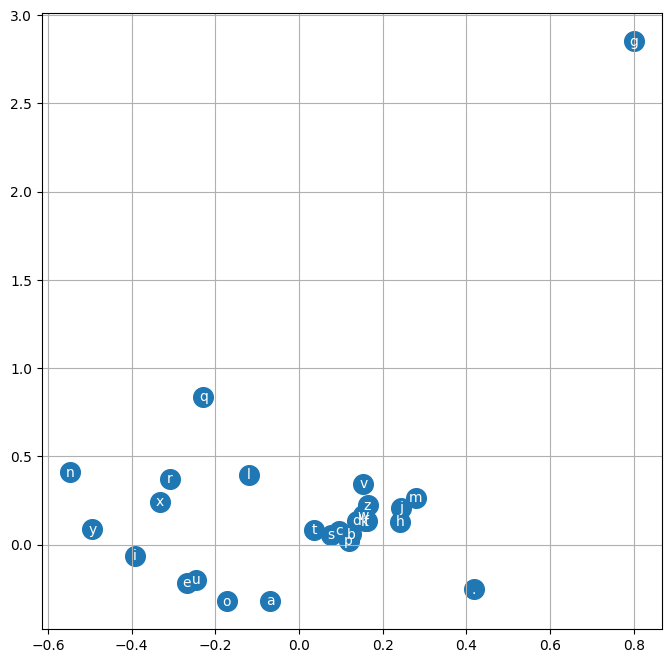

In [ ]:
# lets plot the embeddings C
plt.figure(figsize=(8,8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid("minor")

In [ ]:
# lets try to increase embedding size of each character to increase performance
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [ ]:
for i in range(50000):
    ix = torch.randint(0, Xtr.shape[0], (256,)) # (start, end, size)  <== batch size = 32

    # forward pass
    emb = C[Xtr[ix]]  #### Only get ix rows of X
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix]) # only use ix rows

    # backward pass
    lr = 0.01
    for p in parameters:
        p.grad = None

    loss.backward()
    # update parameters
    for p in parameters:
        p.data += -lr * p.grad

print(f"Epoch {i+1} | loss: {loss.item():.4f}")

Epoch 50000 | loss: 2.2268


In [ ]:
# validate
temb = C[Xdev] 
th = torch.tanh(temb.view(-1, 30) @ W1 + b1)
tlogits = th @ W2 + b2
tloss = F.cross_entropy(tlogits, Ydev)
tloss.item()

2.1977291107177734

In [ ]:
########## sample names using this model
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
        emb = C[torch.tensor([context])] # (1,block_size,d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
            
    print(''.join(itos[i] for i in out))


mona.
kmyaz.
seel.
nihah.
larethan.
endrlee.
adeerdielin.
shy.
jen.
eden.
esmanar.
kayzion.
kamin.
shur.
rishiriel.
kinde.
jeliox.
terofiuzabelle.
jamell.
els.
